In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from ipywidgets import interact, IntSlider, Combobox
from tqdm import tqdm
from ast import literal_eval
import os
from sklearn.model_selection import train_test_split
import json

In [2]:
data_dir = Path('../data/gdphmm-hn/incoming/train')
sample_names = [f.stem for f in data_dir.glob('*.npz')]
len(sample_names)

1427

In [3]:
data = np.load('../data/gdphmm-hn/incoming/train/0522c0001+9Ag+MOS_23629.npz', allow_pickle=True)['arr_0'].item()
sorted(data.keys())

['Body',
 'BrachialPlexus',
 'Brain',
 'BrainStem',
 'BrainStem_03',
 'Chiasm',
 'Cochlea_L',
 'Cochlea_R',
 'Eyes',
 'LacrimalGlands',
 'Larynx',
 'Larynx-PTV',
 'Lens_L',
 'Lens_R',
 'Lips',
 'Lungs',
 'Mandible',
 'Mandible-PTV',
 'OCavity-PTV',
 'OpticNerve_L',
 'OpticNerve_R',
 'OralCavity',
 'PTV70',
 'PTVHighOPT',
 'PTV_Total',
 'ParotidCon-PTV',
 'ParotidIps-PTV',
 'Parotids',
 'Parotids-PTV',
 'PharConst-PTV',
 'PharynxConst',
 'Pituitary',
 'Posterior_Neck',
 'RingPTVHigh',
 'Shoulders',
 'SpinalCord',
 'SpinalCord_05',
 'Submand-PTV',
 'SubmandL-PTV',
 'SubmandR-PTV',
 'Submandibular',
 'Thyroid',
 'Thyroid-PTV',
 'all_mask',
 'angle_list',
 'angle_plate',
 'beam_plate',
 'direction',
 'dose',
 'dose_scale',
 'img',
 'isVMAT',
 'isocenter',
 'origin',
 'size',
 'spacing']

In [4]:
data['PTV70']

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [5]:
for key in data.keys():
    print(key)

    if isinstance(data[key], np.ndarray):
        print(data[key].shape)
    else:
        print(data[key])
    print('-' * 100)

PTV_Total
(124, 103, 169)
----------------------------------------------------------------------------------------------------
ParotidCon-PTV
(124, 103, 169)
----------------------------------------------------------------------------------------------------
ParotidIps-PTV
(124, 103, 169)
----------------------------------------------------------------------------------------------------
Parotids
(124, 103, 169)
----------------------------------------------------------------------------------------------------
Parotids-PTV
(124, 103, 169)
----------------------------------------------------------------------------------------------------
PharConst-PTV
(124, 103, 169)
----------------------------------------------------------------------------------------------------
PharynxConst
(124, 103, 169)
----------------------------------------------------------------------------------------------------
PTV70
(124, 103, 169)
----------------------------------------------------------------------

In [ ]:
paramtools = {
    'sample_name': Combobox(value=sample_names[0], options=sample_names, ensure_option=True),
    'slice_idx': IntSlider(min=0, max=240, step=1)
}

@interact(**paramtools)
def show_interactive(sample_name, slice_idx):
    data = np.load(data_dir / f'{sample_name}.npz', allow_pickle=True)['arr_0'].item()

    print('Dimensions of CT:', data['img'].shape)
    print('Dimensions of Dose:', data['dose'].shape)

    fig, axes = plt.subplots(
        nrows=3,
        ncols=3,
        figsize=(20, 15)
    )

    if slice_idx < data['img'].shape[0]:
      axes[0][0].imshow(data['img'][slice_idx], cmap='gray')
    axes[0][0].axis('off')
    axes[0][0].set_title('View from Axial plane')

    if slice_idx < data['img'].shape[1]:
      axes[0][1].imshow(data['img'][::-1, slice_idx, :], cmap='gray')
    axes[0][1].axis('off')
    axes[0][1].set_title('View from Sagittal plane')

    if slice_idx < data['img'].shape[2]:
      axes[0][2].imshow(data['img'][::-1, ::-1, slice_idx], cmap='gray')
    axes[0][2].axis('off')
    axes[0][2].set_title('View from Coronal plane')

    if slice_idx < data['dose'].shape[0]:
      axes[1][0].imshow(data['dose'][slice_idx], cmap='jet')
    axes[1][0].axis('off')
    axes[1][0].set_title('View from Axial plane')

    if slice_idx < data['dose'].shape[1]:
      axes[1][1].imshow(data['dose'][::-1, slice_idx, :], cmap='jet')
    axes[1][1].axis('off')
    axes[1][1].set_title('View from Sagittal plane')

    if slice_idx < data['dose'].shape[2]:
      print(data['dose'][::-1, ::-1, slice_idx].min(), data['dose'][::-1, ::-1, slice_idx].max())
      axes[1][2].imshow(data['dose'][::-1, ::-1, slice_idx], cmap='jet')
    axes[1][2].axis('off')
    axes[1][2].set_title('View from Coronal plane')

    if slice_idx < data['PTV_Total'].shape[0]:
      axes[2][0].imshow(data['PTV_Total'][slice_idx], cmap='gray')
    axes[2][0].axis('off')
    axes[2][0].set_title('View from Axial plane')

    if slice_idx < data['PTV_Total'].shape[1]:
      axes[2][1].imshow(data['PTV_Total'][::-1, slice_idx, :], cmap='gray')
    axes[2][1].axis('off')
    axes[2][1].set_title('View from Sagittal plane')

    if slice_idx < data['PTV_Total'].shape[2]:
      axes[2][2].imshow(data['PTV_Total'][::-1, ::-1, slice_idx], cmap='gray')
    axes[2][2].axis('off')
    axes[2][2].set_title('View from Coronal plane')

    fig.tight_layout()



interactive(children=(Combobox(value='HNC_189+9Ag+MOS_20547', description='sample_name', ensure_option=True, o…

In [25]:
metadata = []

for sample_name in (pbar := tqdm(sample_names)):
  pbar.set_description(f'Processing {sample_name}')
  data = np.load(data_dir / f'{sample_name}.npz', allow_pickle=True)['arr_0'].item()

  metadata_entry = {
    'sample_name': sample_name
  }

  for key in data.keys():
    if isinstance(data[key], np.ndarray):
      metadata_entry[f'{key}_shape'] = data[key].shape
      metadata_entry[f'{key}_range'] = (data[key].min().item(), data[key].max().item())

      if np.any(data[key] > 0):
        coords = np.argwhere(data[key] > 0)
        min_coords = coords.min(axis=0)
        max_coords = coords.max(axis=0)
        bbox = max_coords - min_coords + 1

        metadata_entry[f'{key}_bbox'] = tuple(min_coords.tolist()) + tuple(bbox.tolist())
      else:
        metadata_entry[f'{key}_bbox'] = np.nan
    else:
      metadata_entry[key] = data[key]

  metadata.append(metadata_entry)



Processing HN_P015+15Ag+MOS_6827: 100%|██████████| 224/224 [01:41<00:00,  2.20it/s]       


In [ ]:
pd.DataFrame(metadata).set_index('sample_name').to_csv('../data/gdphmm-hn/incoming/train_metadata.csv')

In [3]:
metadata = pd.read_csv('../data/gdphmm-hn/incoming/train_metadata.csv')
for col in metadata.columns[metadata.columns.str.endswith(('_shape', '_range', '_bbox'))]:
  metadata[col] = metadata[col].apply(lambda x: literal_eval(x) if isinstance(x, str) else None)

metadata['all_mask'] = metadata['all_mask'].apply(lambda x: literal_eval(x) if isinstance(x, str) else x)

metadata

,sample_name,Trachea_shape,Trachea_range,Trachea_bbox,Thyroid-PTV_shape,Thyroid-PTV_range,Thyroid-PTV_bbox,Thyroid_shape,Thyroid_range,Thyroid_bbox,...,PTVMid_bbox,PTVLowOPT_shape,PTVLowOPT_range,PTVLowOPT_bbox,PTVLow-PTVMid_shape,PTVLow-PTVMid_range,PTVLow-PTVMid_bbox,PTVLow_shape,PTVLow_range,PTVLow_bbox
0,HNC_189+9Ag+MOS_20547,"(128, 108, 177)","(0, 1)","(0, 37, 81, 45, 21, 9)","(128, 108, 177)","(0, 1)","(31, 41, 79, 14, 5, 13)","(128, 108, 177)","(0, 1)","(31, 41, 79, 14, 5, 13)",...,None,None,None,None,None,None,None,None,None,None
1,HN-CHUM-039+S29Ag+MOS_24568,"(128, 107, 176)","(0, 1)","(0, 35, 85, 29, 17, 10)","(128, 107, 176)","(0, 1)","(12, 36, 82, 20, 11, 18)","(128, 107, 176)","(0, 1)","(12, 36, 82, 20, 11, 18)",...,None,None,None,None,None,None,None,None,None,None
2,HNSCC-01-0054+A4Ac+MOS_0511,None,None,None,"(128, 101, 194)","(0, 1)","(12, 31, 84, 24, 11, 21)","(128, 101, 194)","(0, 1)","(12, 31, 84, 24, 11, 21)",...,"(45, 22, 84, 35, 41, 43)","(128, 101, 194)","(0, 1)","(45, 33, 67, 51, 26, 46)","(128, 101, 194)","(0, 1)","(45, 33, 67, 51, 26, 46)","(128, 101, 194)","(0, 1)","(45, 33, 67, 51, 26, 46)"
3,HNC_171+A4Ac+MOS_31950,"(128, 109, 193)","(0, 1)","(0, 39, 89, 47, 24, 13)","(128, 109, 193)","(0, 1)","(32, 41, 91, 15, 6, 14)","(128, 109, 193)","(0, 1)","(31, 41, 89, 16, 7, 17)",...,None,"(128, 109, 193)","(0, 1)","(23, 22, 63, 79, 47, 67)","(128, 109, 193)","(0, 1)","(23, 22, 63, 79, 47, 67)","(128, 109, 193)","(0, 1)","(23, 22, 63, 79, 47, 67)"
4,HNC_027+A4Ac+MOS_17377,"(132, 111, 180)","(0, 1)","(0, 34, 85, 30, 21, 11)","(132, 111, 180)","(0, 1)","(14, 34, 81, 22, 13, 20)","(132, 111, 180)","(0, 1)","(14, 34, 80, 24, 13, 22)",...,"(53, 38, 68, 37, 29, 21)","(132, 111, 180)","(0, 1)","(17, 8, 50, 108, 62, 68)","(132, 111, 180)","(0, 1)","(17, 8, 50, 108, 62, 68)","(132, 111, 180)","(0, 1)","(17, 8, 50, 108, 62, 68)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1422,HNSCC-01-0091+A4Ac+MOS_43410,"(128, 102, 200)","(0, 1)","(0, 31, 95, 22, 23, 13)","(128, 102, 200)","(0, 1)","(9, 34, 91, 21, 12, 23)","(128, 102, 200)","(0, 1)","(9, 34, 91, 21, 12, 23)",...,"(42, 16, 72, 43, 52, 43)","(128, 102, 200)","(0, 1)","(42, 27, 85, 56, 40, 46)","(128, 102, 200)","(0, 1)","(42, 27, 85, 56, 40, 46)","(128, 102, 200)","(0, 1)","(42, 27, 85, 56, 40, 46)"
1423,HNC_033+15Ag+MOS_1673,"(128, 129, 187)","(0, 1)","(0, 44, 86, 33, 26, 12)","(128, 129, 187)","(0, 1)","(19, 44, 83, 15, 14, 19)","(128, 129, 187)","(0, 1)","(19, 44, 81, 19, 14, 24)",...,"(30, 24, 69, 77, 46, 46)","(128, 129, 187)","(0, 1)","(17, 43, 49, 35, 42, 87)","(128, 129, 187)","(0, 1)","(17, 43, 49, 35, 42, 87)","(128, 129, 187)","(0, 1)","(17, 43, 49, 35, 42, 87)"
1424,HN-CHUM-065+S215Ag+MOS_28286,None,None,None,"(128, 98, 180)","(0, 1)","(4, 36, 81, 20, 13, 20)","(128, 98, 180)","(0, 1)","(4, 36, 81, 20, 13, 20)",...,None,"(128, 98, 180)","(0, 1)","(40, 25, 63, 49, 31, 35)","(128, 98, 180)","(0, 1)","(40, 24, 63, 49, 33, 36)","(128, 98, 180)","(0, 1)","(40, 24, 63, 49, 33, 36)"
1425,HN-CHUM-033+S29Ag+MOS_1226,"(128, 118, 200)","(0, 1)","(0, 39, 95, 37, 31, 13)","(128, 118, 200)","(0, 1)","(25, 41, 92, 17, 12, 19)","(128, 118, 200)","(0, 1)","(25, 41, 92, 17, 12, 21)",...,"(35, 28, 74, 74, 43, 70)","(128, 118, 200)","(0, 1)","(22, 39, 65, 39, 23, 71)","(128, 118, 200)","(0, 1)","(22, 39, 65, 39, 23, 73)","(128, 118, 200)","(0, 1)","(22, 39, 65, 39, 23, 73)"


In [4]:
np.array(metadata[metadata['PTV70_bbox'] != metadata['PTVHighOPT_bbox']][['PTV70_bbox', 'PTVHighOPT_bbox']])

array([[(43, 36, 79, 42, 30, 31), (43, 36, 79, 42, 30, 30)],
       [(37, 24, 90, 50, 33, 29), (37, 24, 90, 50, 33, 30)],
       [(37, 23, 74, 60, 38, 55), (37, 23, 74, 60, 38, 54)],
       [(20, 16, 74, 72, 57, 64), (20, 16, 74, 72, 57, 65)],
       [(45, 33, 104, 40, 27, 33), (45, 33, 104, 40, 27, 32)],
       [(20, 16, 74, 72, 57, 64), (20, 16, 74, 72, 57, 65)],
       [(43, 36, 79, 42, 30, 31), (43, 36, 79, 42, 30, 30)],
       [(51, 29, 65, 36, 21, 40), (53, 29, 65, 34, 21, 40)],
       [(37, 24, 90, 50, 33, 29), (37, 24, 90, 50, 33, 30)],
       [(40, 32, 76, 50, 26, 32), (40, 32, 76, 50, 25, 32)],
       [(40, 24, 87, 64, 31, 22), (40, 24, 86, 64, 31, 23)],
       [(40, 32, 76, 50, 26, 32), (40, 32, 76, 50, 25, 32)],
       [(55, 28, 68, 45, 36, 55), (55, 28, 68, 45, 36, 56)],
       [(40, 24, 87, 64, 31, 22), (40, 24, 86, 64, 31, 23)],
       [(43, 14, 69, 44, 41, 31), (43, 14, 69, 43, 41, 31)],
       [(37, 23, 74, 60, 38, 55), (37, 23, 74, 60, 38, 54)],
       [(51, 29, 65, 3

In [5]:
missings = metadata.isna().sum()
missings.sort_values(ascending=False)

SubmandR-PTV_bbox      672
Lens_L_bbox            663
Lens_R_bbox            645
SubmandL-PTV_bbox      607
Chiasm_bbox            560
                      ... 
Body_bbox                0
Body_range               0
Body_shape               0
BrachialPlexus_bbox      0
sample_name              0
Length: 183, dtype: int64

In [ ]:
img_shapes[:, 0].

array([[128, 108, 177],
       [128, 107, 176],
       [128, 101, 194],
       ...,
       [128,  98, 180],
       [128, 118, 200],
       [128, 141, 183]], shape=(1427, 3))

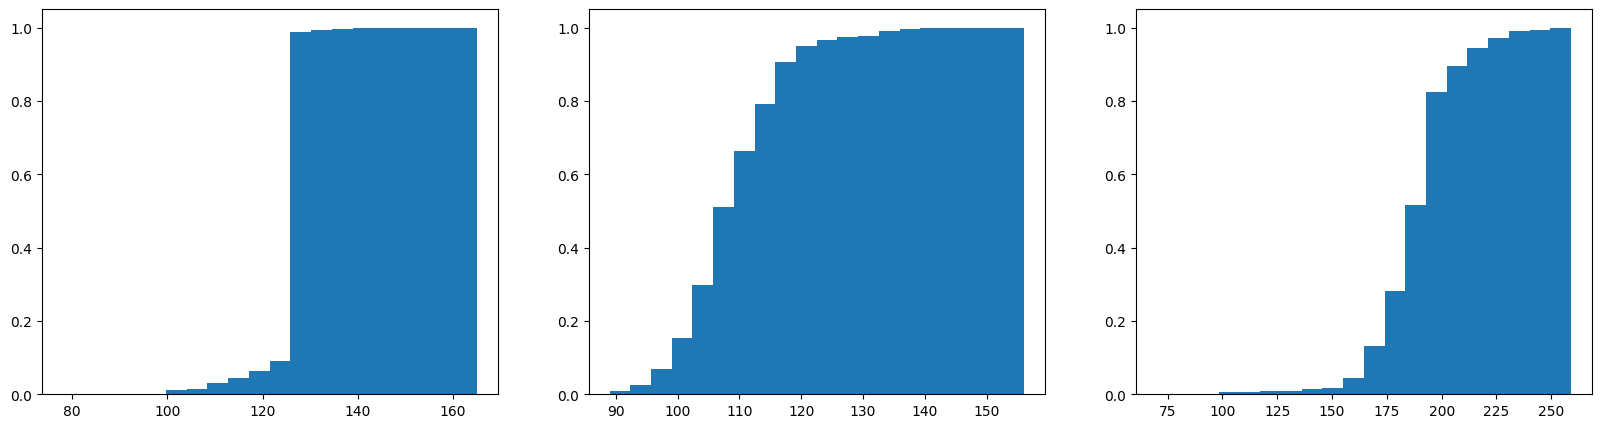

In [6]:
img_shapes = np.array(metadata['img_shape'].tolist())

fig, axs = plt.subplots(1, 3, figsize=(20, 5))
for i in range(3):
  axs[i].hist(img_shapes[:, i], cumulative=True, density=True, bins=20)

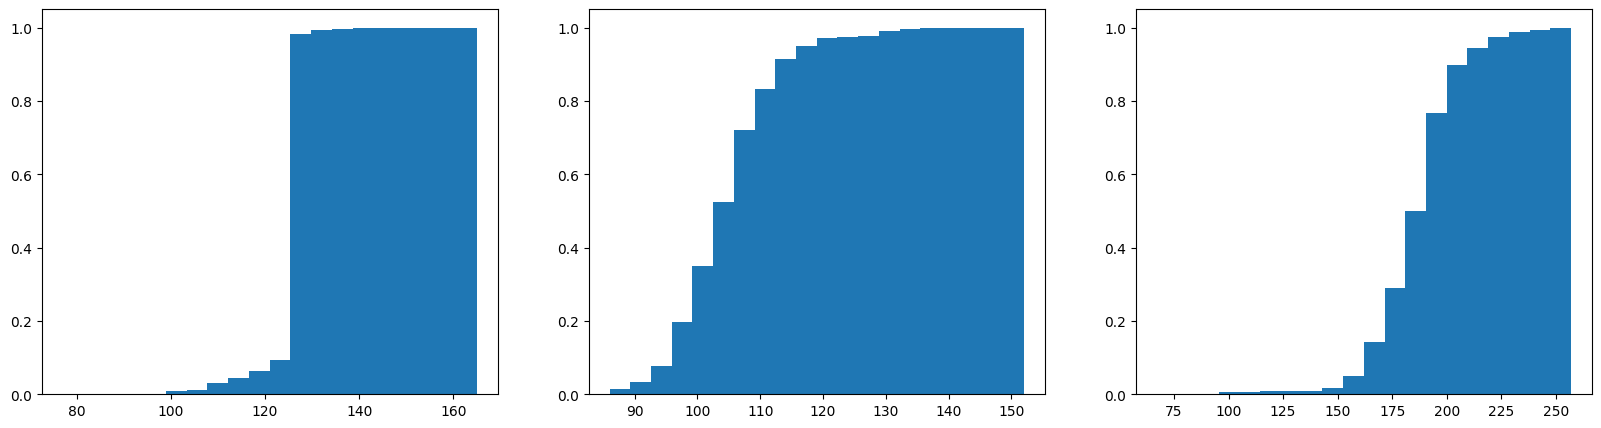

In [10]:
body_bboxes = np.array(metadata['Body_bbox'].tolist())

fig, axs = plt.subplots(1, 3, figsize=(20, 5))
for i in range(3):
  axs[i].hist(body_bboxes[:, 3 + i], cumulative=True, density=True, bins=20)

In [11]:
img_shapes = np.array(metadata['img_shape'].tolist())
img_shapes.min(axis=0), img_shapes.max(axis=0)

(array([78, 89, 70]), array([165, 156, 259]))

In [12]:
img_shapes = np.array(metadata['Body_bbox'].tolist())
img_shapes.min(axis=0), img_shapes.max(axis=0)

(array([ 0,  0,  0, 77, 86, 67]), array([  3,   3,   3, 165, 152, 257]))

In [13]:
all_masks = sorted(metadata['all_mask'].explode().unique())
all_masks

['Body',
 'BrachialPlexus',
 'Brain',
 'BrainStem',
 'BrainStem_03',
 'Chiasm',
 'Cochlea_L',
 'Cochlea_R',
 'Esophagus',
 'Eyes',
 'LacrimalGlands',
 'Larynx',
 'Larynx-PTV',
 'Lens_L',
 'Lens_R',
 'Lips',
 'Lungs',
 'Mandible',
 'Mandible-PTV',
 'OCavity-PTV',
 'OpticNerve_L',
 'OpticNerve_R',
 'OralCavity',
 'PTV56',
 'PTV56-PTV63',
 'PTV56OPT',
 'PTV63',
 'PTV63-PTV70',
 'PTV63OPT',
 'PTV70',
 'PTV70OPT',
 'PTV_Total',
 'ParotidCon-PTV',
 'ParotidIps-PTV',
 'Parotids',
 'Parotids-PTV',
 'PharConst-PTV',
 'PharynxConst',
 'Pituitary',
 'Posterior_Neck',
 'RingPTV56',
 'RingPTV63',
 'RingPTV70',
 'Shoulders',
 'SpinalCord',
 'SpinalCord_05',
 'Submand-PTV',
 'SubmandL-PTV',
 'SubmandR-PTV',
 'Submandibular',
 'Thyroid',
 'Thyroid-PTV',
 'Trachea']

In [14]:
# from https://github.com/RiqiangGao/GDP-HMM_AAPMChallenge/blob/main/data_loader.py#L171
HaN_OAR_LIST = [ 'Cochlea_L', 'Cochlea_R','Eyes', 'Lens_L', 'Lens_R', 'OpticNerve_L', 'OpticNerve_R', 'Chiasim', 'LacrimalGlands', 'BrachialPlexus', 'Brain',  'BrainStem_03',  'Esophagus', 'Lips', 'Lungs', 'Trachea', 'Posterior_Neck', 'Shoulders', 'Larynx-PTV', 'Mandible-PTV', 'OCavity-PTV', 'ParotidCon-PTV', 'ParotidIps-PTV', 'Parotids-PTV', 'PharConst-PTV', 'Submand-PTV', 'SubmandL-PTV', 'SubmandR-PTV', 'Thyroid-PTV', 'SpinalCord_05']

print('additional in all_masks', set(all_masks) - set(HaN_OAR_LIST))
print('additional in HaN_OAR_LIST', set(HaN_OAR_LIST) - set(all_masks))

additional in all_masks {'PTV56OPT', 'Mandible', 'PTV70', 'BrainStem', 'Chiasm', 'PTV63', 'PharynxConst', 'Submandibular', 'SpinalCord', 'PTV63-PTV70', 'PTV63OPT', 'OralCavity', 'Pituitary', 'Parotids', 'Thyroid', 'PTV56', 'RingPTV63', 'Body', 'Larynx', 'RingPTV56', 'PTV70OPT', 'PTV56-PTV63', 'RingPTV70', 'PTV_Total'}
additional in HaN_OAR_LIST {'Chiasim'}


In [15]:
img_ranges = np.array(metadata['img_range'].tolist())
img_ranges.min(axis=0), img_ranges.max(axis=0)

(array([-4035.,  1623.]), array([-1066., 21265.]))

In [16]:
img_ranges[:, 0].min(), img_ranges[:, 1].max()

(np.float64(-4035.0), np.float64(21265.0))

In [17]:
len(img_ranges[img_ranges[:, 0] < 1024])

1427

<Axes: >

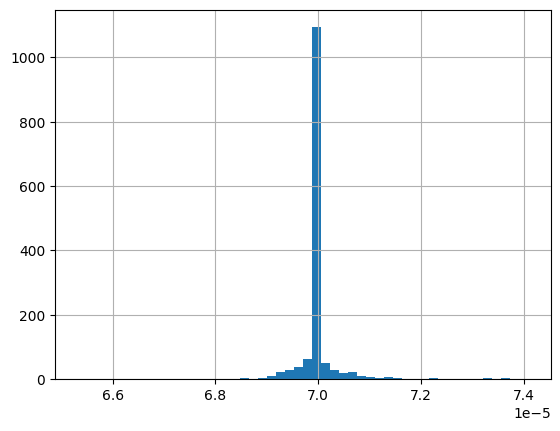

In [18]:
metadata['dose_scale'].hist(bins=50)

In [19]:
# min is 0 for all samples
doses = np.array(metadata['dose_range'].tolist())[:, 1] * metadata['dose_scale']
np.max(doses)

np.float64(121.72187999999998)

In [20]:
np.percentile(doses, 99.5)

np.float64(88.35117268576998)

(array([  2.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   3.,
         20.,  67.,  60.,  35., 121.,  38., 678., 312.,  42.,  21.,   9.,
          6.,   7.,   1.,   1.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,
          0.,   0.,   1.,   0.,   0.,   2.]),
 array([ 11.11920236,  13.33125592,  15.54330947,  17.75536302,
         19.96741657,  22.17947013,  24.39152368,  26.60357723,
         28.81563078,  31.02768434,  33.23973789,  35.45179144,
         37.663845  ,  39.87589855,  42.0879521 ,  44.30000565,
         46.51205921,  48.72411276,  50.93616631,  53.14821986,
         55.36027342,  57.57232697,  59.78438052,  61.99643408,
         64.20848763,  66.42054118,  68.63259473,  70.84464829,
         73.05670184,  75.26875539,  77.48080895,  79.6928625 ,
         81.90491605,  84.1169696 ,  86.32902316,  88.54107671,
         90.75313026,  92.96518381,  95.17723737,  97.38929092,
         99.601344

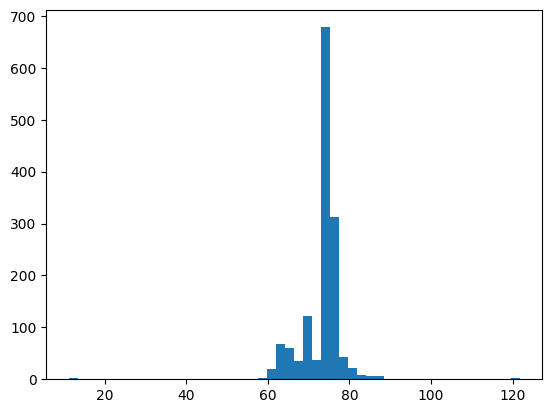

In [21]:
plt.hist(doses, bins=50)

In [26]:
metadata[metadata['Submand-PTV_range'].isna()][['SubmandL-PTV_range', 'SubmandR-PTV_range']]

,SubmandL-PTV_range,SubmandR-PTV_range
3,None,None
21,None,None
47,None,None
50,None,None
57,None,None
...,...,...
1375,None,None
1389,None,None
1400,None,None
1415,None,None


In [30]:
metadata[metadata['Parotids-PTV_range'].isna()][['ParotidIps-PTV_range', 'ParotidCon-PTV_range']]

,ParotidIps-PTV_range,ParotidCon-PTV_range


## Data Split

In [ ]:
base_dir = Path('../data/gdphmm-hn-vmat')
test_dir = base_dir / 'test'
test_dir.mkdir(exist_ok=True)

in_valid_files = (base_dir / 'incoming/valid').glob('*.npz')

for file in tqdm(in_valid_files, desc='Linking test files'):
  link_path = test_dir / file.name
  if link_path.exists():
    link_path.unlink()

  relative_target = file.relative_to(base_dir)
  link_path.symlink_to(Path('..') / relative_target)


Linking test files: 224it [00:00, 1810.42it/s]


In [81]:
in_train_dir = Path('../data/gdphmm-hn/incoming/train')
in_train_files = [f.stem for f in in_train_dir.glob('*.npz')]

in_metadata = pd.read_csv('../data/gdphmm-hn/incoming/metadata.csv')
in_metadata['file'] = in_metadata['npz_path'].apply(lambda x: Path(x).stem)
in_metadata = in_metadata[in_metadata['file'].isin(in_train_files)]
len(in_metadata)

1425

In [82]:
len(in_train_files)

1427

In [83]:
set(in_train_files) - set(in_metadata['file'])

{'HN-CHUS-100+S215Ag+MOS_4436', 'HN-CHUS-100+S29Ag+MOS_4436'}

In [84]:
pd.read_csv('../data/gdphmm-hn/incoming/metadata.csv')['cohort'].value_counts()

cohort
2    1124
1    1038
3     519
4     483
5      68
Name: count, dtype: int64

In [85]:
in_metadata['PID'].value_counts()

PID
0522c0001        3
HNC_176          3
HNC_198          3
HNC_196          3
HNC_195          3
                ..
HNC_010          1
HNC_178          1
0522c0883        1
HNSCC-01-0181    1
HNC_091          1
Name: count, Length: 498, dtype: int64

In [86]:
groups = in_metadata.groupby('PID')['cohort'].max()
groups.index.value_counts().max()
# every PID has one cohort, so this is 1

np.int64(1)

In [87]:
train_pid, valid_pid = train_test_split(groups.index, test_size=0.07, random_state=42, shuffle=True, stratify=groups.values)
len(train_pid), len(valid_pid)

(463, 35)

In [88]:
train_files = in_metadata[in_metadata['isVMAT'] & in_metadata['PID'].isin(train_pid)]['file'].tolist()
valid_files = in_metadata[in_metadata['isVMAT'] & in_metadata['PID'].isin(valid_pid)]['file'].tolist()
len(train_files), len(valid_files)

(440, 32)

In [74]:
train_dir = base_dir / 'train'
train_dir.mkdir(exist_ok=True)

valid_dir = base_dir / 'valid'
valid_dir.mkdir(exist_ok=True)

for file in tqdm(train_files, desc='Linking train files'):
  link_path = train_dir / f'{file}.npz'
  if link_path.exists():
    link_path.unlink()

  relative_target = (in_train_dir / f'{file}.npz').relative_to(base_dir)
  link_path.symlink_to(Path('..') / relative_target)

for file in tqdm(valid_files, desc='Linking valid files'):
  link_path = valid_dir / f'{file}.npz'
  if link_path.exists():
    link_path.unlink()

  relative_target = (in_train_dir / f'{file}.npz').relative_to(base_dir)
  link_path.symlink_to(Path('..') / relative_target)

Linking valid files: 100%|██████████| 98/98 [00:00<00:00, 7017.12it/s]


## Index Files

In [4]:
base_dir = Path('../data/gdphmm-hn-vmat')
split = 'valid'
files = list((base_dir / split).glob('*.npz'))

index_map = []
for file in tqdm(files, desc=f'Indexing Dataset {split}'):
  vol = np.load(file, allow_pickle=True)['arr_0'].item()
  n_slices = vol['img'].shape[2]
  for idx in range(n_slices):
    index_map.append((file.name, idx))

index_map = pd.DataFrame(index_map, columns=['file', 'slice_idx'])
index_map.to_csv(base_dir / split / '_index.csv', index=False)

Indexing Dataset valid: 100%|██████████| 9/9 [00:01<00:00,  6.57it/s]


## Data Split 2

In [91]:
in_train_dir = Path('../data/gdphmm-hn/incoming/train')
in_train_files = [f.stem for f in in_train_dir.glob('*.npz')]

in_metadata = pd.read_csv('../data/gdphmm-hn/incoming/metadata.csv')
in_metadata['file'] = in_metadata['npz_path'].apply(lambda x: Path(x).stem)
in_metadata = in_metadata[in_metadata['file'].isin(in_train_files)]
len(in_metadata)

1425

In [92]:
in_metadata = in_metadata[in_metadata['isVMAT']]
len(in_metadata)

472

In [96]:
train_valid_metadata, test_metadata = train_test_split(in_metadata, test_size=0.1, random_state=42, shuffle=True, stratify=in_metadata['cohort'].values)
len(train_valid_metadata), len(test_metadata)

(424, 48)

In [99]:
train_metadata, valid_metadata = train_test_split(train_valid_metadata, test_size=0.02, random_state=42, shuffle=True, stratify=train_valid_metadata['cohort'].values)
len(train_metadata), len(valid_metadata)

(415, 9)

In [102]:
train_files = train_metadata['file'].tolist()
valid_files = valid_metadata['file'].tolist()
len(train_files), len(valid_files)

(415, 9)

In [112]:
base_dir = Path('../data/gdphmm-hn-vmat')
train_dir = base_dir / 'train'
train_dir.mkdir(exist_ok=True, parents=True)

valid_dir = base_dir / 'valid'
valid_dir.mkdir(exist_ok=True, parents=True)

test_dir = base_dir / 'test'
test_dir.mkdir(exist_ok=True, parents=True)

rel_dir = base_dir

for file in tqdm(train_metadata['file'].tolist(), desc='Linking train files'):
  link_path = train_dir / f'{file}.npz'
  if link_path.exists():
    link_path.unlink()

  relative_target = Path(os.path.relpath(in_train_dir / f'{file}.npz', start=link_path.parent))
  link_path.symlink_to(relative_target)

for file in tqdm(valid_metadata['file'].tolist(), desc='Linking valid files'):
  link_path = valid_dir / f'{file}.npz'
  if link_path.exists():
    link_path.unlink()

  relative_target = Path(os.path.relpath(in_train_dir / f'{file}.npz', start=link_path.parent))
  link_path.symlink_to(relative_target)

for file in tqdm(test_metadata['file'].tolist(), desc='Linking valid files'):
  link_path = test_dir / f'{file}.npz'
  if link_path.exists():
    link_path.unlink()

  relative_target = Path(os.path.relpath(in_train_dir / f'{file}.npz', start=link_path.parent))
  link_path.symlink_to(relative_target)

Linking valid files: 100%|██████████| 48/48 [00:00<00:00, 4876.03it/s]


## OAR Lists

In [10]:
all_oar_list = {
  'Cochlea_L', 'Cochlea_R', 'Eyes', 'Lens_L', 'Lens_R', 'OpticNerve_L', 'OpticNerve_R',
  'Chiasm', 'LacrimalGlands', 'BrachialPlexus', 'Brain', 'BrainStem_03', 'Esophagus',
  'Lips', 'Lungs', 'Trachea', 'Posterior_Neck', 'Shoulders', 'Larynx-PTV', 'Mandible-PTV',
  'OCavity-PTV', 'ParotidCon-PTV', 'ParotidIps-PTV', 'Parotids-PTV', 'PharConst-PTV',
  'Submand-PTV', 'SubmandL-PTV', 'SubmandR-PTV', 'Thyroid-PTV', 'SpinalCord_05',
}

with open('../data/gdphmm-hn/incoming/Pat_Obj_DICT.json', 'r') as json_file:
  oar_list = json.load(json_file)

found_oars = set()
for key in sample_names:
  id = key.split('+')[0]
  found_oars.update(oar_list[id])

len(found_oars)

46

In [11]:
all_oar_list - found_oars

{'BrachialPlexus', 'LacrimalGlands'}